In [1]:
!pip install statsbombpy mplsoccer


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [mplsoccer]


In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from statsbombpy import sb

# 1. Carregar jogos do Mundial 2022
matches = sb.matches(competition_id=43, season_id=106)

all_events = []
for match_id in matches['match_id']:
    events = sb.events(match_id=match_id)
    shots = events[events['type'] == 'Shot'].copy()
    all_events.append(shots)

df_shots = pd.concat(all_events, ignore_index=True)

# 2. Filtrar penáltis e extrair coordenadas
df_shots = df_shots[df_shots['shot_type'] != 'Penalty'].copy()
df_shots['x'] = df_shots['location'].apply(lambda loc: loc[0])
df_shots['y'] = df_shots['location'].apply(lambda loc: loc[1])
df_shots['is_goal'] = (df_shots['shot_outcome'] == 'Goal').astype(int)

# 3. Feature Engineering Geométrico
goal_x, goal_y, goal_width = 120.0, 40.0, 8.0
dx = goal_x - df_shots['x']
dy = np.abs(df_shots['y'] - goal_y)

df_shots['distance'] = np.sqrt(dx**2 + dy**2)

numerator = goal_width * dx
denominator = dx**2 + dy**2 - (goal_width / 2)**2
angle = np.arctan2(numerator, denominator)
df_shots['angle_rad'] = np.where(angle < 0, angle + np.pi, angle)
df_shots['angle_deg'] = np.degrees(df_shots['angle_rad'])

df_shots['is_header'] = (df_shots['shot_body_part'] == 'Head').astype(int)
df_shots['under_pressure'] = df_shots['under_pressure'].fillna(False).astype(int)
df_shots['is_counter_attack'] = (df_shots['play_pattern'] == 'From Counter').astype(int)

print(f"Remates analisados: {len(df_shots)} | Taxa de golo: {df_shots['is_goal'].mean():.2%}")

Remates analisados: 1430 | Taxa de golo: 10.63%


              Model  Log-Loss (lower is better)  Brier Score (lower is better)  ROC-AUC (higher is better)
Logistic Regression                    0.277584                       0.081895                    0.810773
  Gradient Boosting                    0.280617                       0.082235                    0.796834


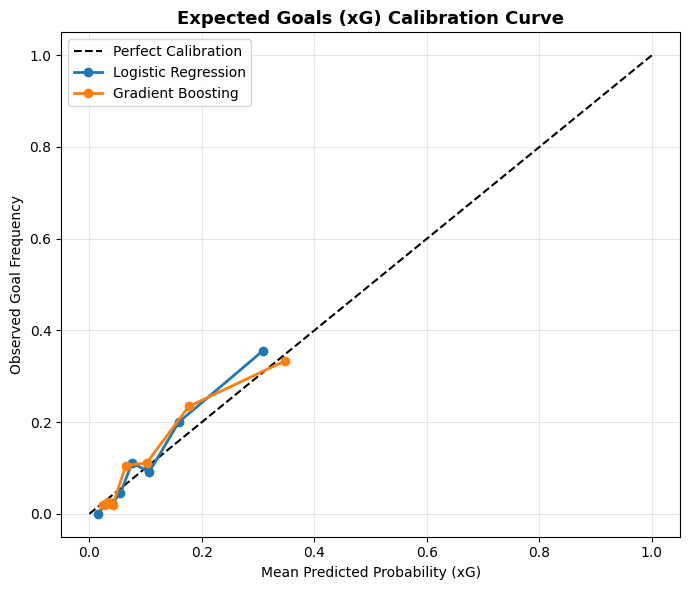

In [3]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score
from sklearn.calibration import calibration_curve

features = ['distance', 'angle_rad', 'is_header', 'under_pressure', 'is_counter_attack']
X = df_shots[features]
y = df_shots['is_goal']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# Modelos
lr = LogisticRegression()
gb = GradientBoostingClassifier(n_estimators=100, max_depth=3, learning_rate=0.05, random_state=42)

lr.fit(X_train, y_train)
gb.fit(X_train, y_train)

probs_lr = lr.predict_proba(X_test)[:, 1]
probs_gb = gb.predict_proba(X_test)[:, 1]

# Tabela comparativa de métricas
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Gradient Boosting'],
    'Log-Loss (lower is better)': [log_loss(y_test, probs_lr), log_loss(y_test, probs_gb)],
    'Brier Score (lower is better)': [brier_score_loss(y_test, probs_lr), brier_score_loss(y_test, probs_gb)],
    'ROC-AUC (higher is better)': [roc_auc_score(y_test, probs_lr), roc_auc_score(y_test, probs_gb)]
})
print(results.to_string(index=False))

# Gráfico: Curva de Calibração
plt.figure(figsize=(7, 6))
plt.plot([0, 1], [0, 1], 'k--', label='Perfect Calibration')

for name, probs in [('Logistic Regression', probs_lr), ('Gradient Boosting', probs_gb)]:
    prob_true, prob_pred = calibration_curve(y_test, probs, n_bins=8, strategy='quantile')
    plt.plot(prob_pred, prob_true, marker='o', linewidth=2, label=name)

plt.title('Expected Goals (xG) Calibration Curve', fontsize=13, fontweight='bold')
plt.xlabel('Mean Predicted Probability (xG)')
plt.ylabel('Observed Goal Frequency')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('calibration_curve.png', dpi=300)
plt.show()

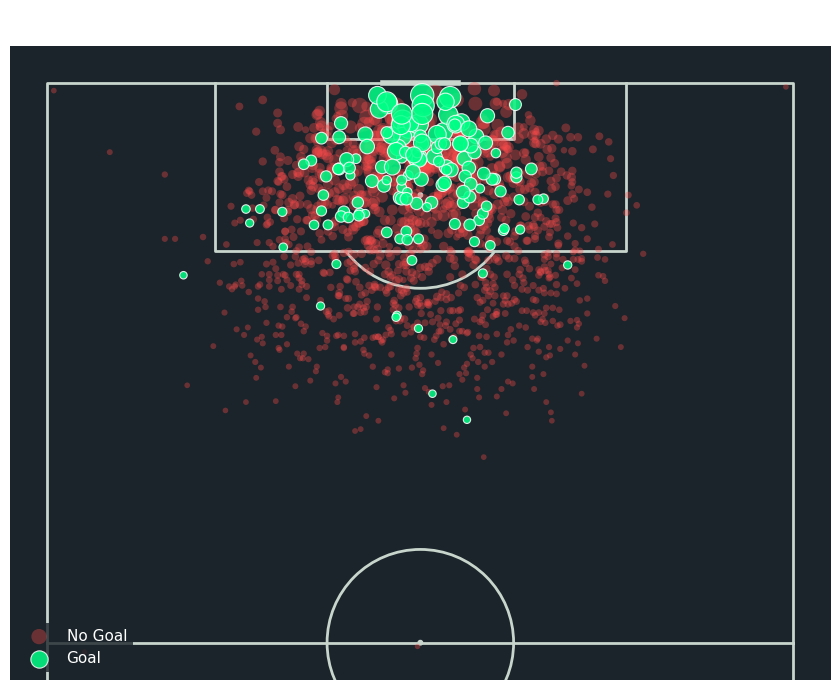

In [4]:
from mplsoccer import VerticalPitch

# Calcular xG previsto para todos os remates com Regressão Logística
df_shots['xG'] = lr.predict_proba(X)[:, 1]

pitch = VerticalPitch(pitch_type='statsbomb', half=True, pitch_color='#1b242a', line_color='#c7d5cc')
fig, ax = pitch.draw(figsize=(10, 7))

goals = df_shots[df_shots['is_goal'] == 1]
no_goals = df_shots[df_shots['is_goal'] == 0]

# Remates falhados
pitch.scatter(no_goals['x'], no_goals['y'], s=no_goals['xG']*300 + 15,
              color='#ff4b4b', alpha=0.35, edgecolors='none', label='No Goal', ax=ax)

# Golos
pitch.scatter(goals['x'], goals['y'], s=goals['xG']*300 + 25,
              color='#00ff87', alpha=0.85, edgecolors='white', linewidth=0.8, label='Goal', ax=ax)

ax.set_title('World Cup 2022 — Spatial Shot Map Sized by Predicted xG', color='white', fontsize=14, fontweight='bold', pad=15)
ax.legend(facecolor='#1b242a', edgecolor='none', labelcolor='white', loc='lower left', fontsize=11)

plt.tight_layout()
plt.savefig('xg_shot_map.png', dpi=300, facecolor='#1b242a')
plt.show()